Constraint Diagram


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from ambiance import Atmosphere
import pint
ureg = pint.UnitRegistry()

MTOW=45000 #[lbm] note: PLACEHOLDER
C_d_min=0.02 # Taken from The annual aircraft design book (blue), page 6-7. 
AR=10 # competitively assessed
e=0.85 # competitively assessed
k=1/(np.pi*e*AR)
M_cruise=0.55 #cruise mach, competitively assessed 
alt=20000*ureg.feet #cruise altitude [input feet], competitively assessed
take_off_distance=(3900*ureg.feet).magnitude # [ft] landing and takeoff distance at sea level, competitively estimated 
take_off_alt=(0*ureg.feet).magnitude #[ft] density altitude of takeoff



$$ W_l= X * MTOW $$

This was derived with the following: 
$ W_L=W_{TO}\left[\frac{W_{pl}}{W_{TO}}+EWF+  (\approx{0})\right] $ From sizing excel sheet we have an estimate for $W_{TO}, EWF, \frac{W_{pl}}{W_{TO}}$,which yields 0.91 for now (subject to change). 

In [74]:
EWF=0.62
W_p=13325
W_landing_fraction=(W_p/MTOW+EWF) # see notes above, this is (X) 
print("Landing weight fraction: ", W_landing_fraction)

Landing weight fraction:  0.9161111111111111


Cruise Velocity Constraint: We need to be able to maintain a cruise speed


In [75]:
# cruise velocity constraint

sealevel = Atmosphere(0) # gives SI 
# NOTE: THIS CHANGES WITH ALTITUDE, current: 20000 ft
a_cruisealt = (Atmosphere(alt.to("meters").magnitude).speed_of_sound)*ureg("m/s").to("ft/s").magnitude # ISA to find speed of sound, convert to (ft/s)
rho_cruisealt=Atmosphere(alt.to("meters").magnitude).density*ureg("kg/m^3").to("slug/ft^3").magnitude # ISA to find density at cruise altitude (slug/ft^3)
rho_sl=sealevel.density*ureg("kg/m^3").to("slug/ft^3").magnitude # sea-level slug/ft^3
V_cruise=M_cruise*a_cruisealt #ft/sec
W_S=np.linspace(1, 200, 100) # linspace for wingload
q_cruise=0.5*rho_cruisealt*V_cruise**2 # dynamic pressure at cruise
T_W_cruise=q_cruise*C_d_min*(1/W_S)+(k/q_cruise)*W_S # above line = valid



Takeoff Constraint: Must be able to takeoff off for a required takeoff distance

In [76]:
# takeoff constraint
C_L_max_TO=1.7 # Value from Roskam, page 91 and page 377 from Gudmundsson
TOP_25=take_off_distance/37.5 # Taken from Roskam, page 98
sigma_sl=np.sqrt(rho_sl/rho_sl) #normalizing density (assuming sea level for now)
T_W_takeoff=W_S/(C_L_max_TO*sigma_sl*TOP_25) # Note, above line here (Roskam, page 98, equation 3.7)



In [ ]:
# landing constraint
V_approach=np.sqrt(take_off_distance/0.3) #roskam page 111 (NOTE: verify this works for part 25)

V_sl = V_approach/1.3 # page 111 roskam , in knots, need to convert to ft/sec
V_sl = V_sl*1.68781 # convert knots to ft/sec
C_L_max_L = 2.15 # page 91 roskam (estimated, competitive)
W_S_landing = V_sl**2*rho_sl*0.5*C_L_max_L # roskam equation 3.1 

W_S_landing=W_S_landing/W_landing_fraction # normalize by weight fraction to get in terms of takeoff w/s
print(f"W_S_landing: {W_S_landing}")

W_S_landing: [61.11862882]


Light Design Point: W/S=27.4, T/W=0.155
S=1639.4 ft^2, T=6986.4 lbf


<IPython.core.display.Math object>

------------------
Heavy Design Point: W/S=61.1, T/W=0.346
S=736.3 ft^2, T=15556.2 lbf


<IPython.core.display.Math object>

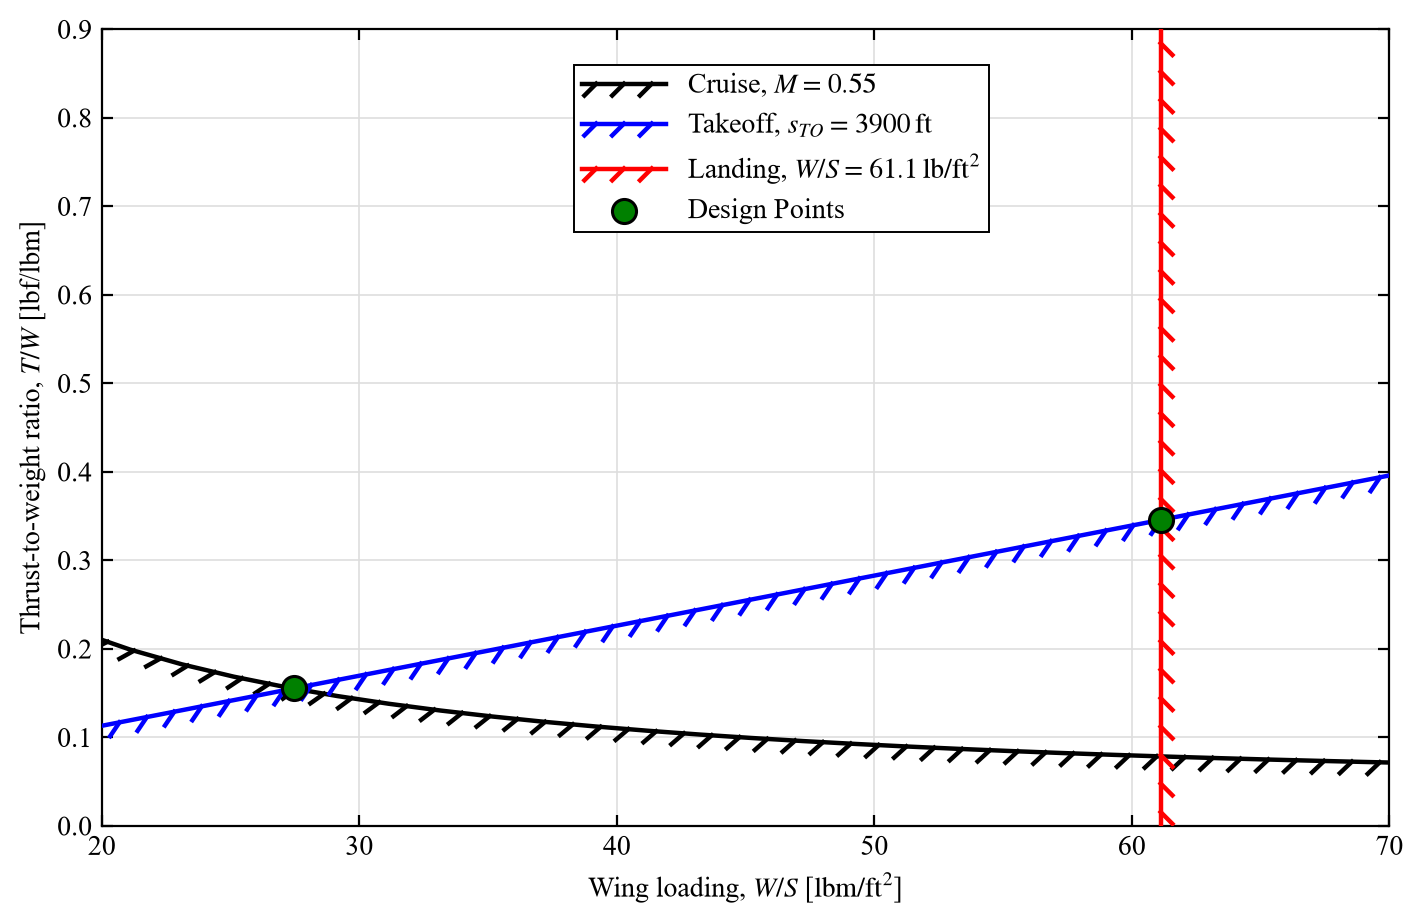

In [79]:
# AIAA-style constraint diagram
# The 7.0-in width is suitable for a two-column AIAA figure.
from IPython.display import Math, display
plt.rcParams.update({
    'font.family': 'times new roman',
    'font.serif': ['STIX Two Text', 'Times New Roman', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'font.size': 12,
    'axes.labelsize': 10,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.linewidth': 0.8,
})

# Design point 1: cruise/takeoff crossover (linear interpolation).
difference = T_W_cruise - T_W_takeoff
crossing_index = np.where(np.diff(np.sign(difference)) != 0)[0][0]
W_S_crossover = np.interp(
    0.0,
    difference[crossing_index:crossing_index + 2][::-1],
    W_S[crossing_index:crossing_index + 2][::-1],
)
T_W_crossover = np.interp(W_S_crossover, W_S, T_W_takeoff)

# Design point 2: takeoff requirement at the landing wing-loading limit.
T_W_landing_design = np.interp(W_S_landing.item(), W_S, T_W_takeoff)

fig, ax = plt.subplots(
    figsize=(7.0, 4.5),
    dpi=200,                 # controls the displayed figure
    constrained_layout=True,
)

cruise_line, = ax.plot(
    W_S, T_W_cruise, color='black', lw=1.6,
    label=rf'Cruise, $M={M_cruise:.2f}$', zorder=3,
)
takeoff_line, = ax.plot(
    W_S, T_W_takeoff, color='blue', lw=1.6,
    label=rf'Takeoff, $s_{{TO}}={take_off_distance:.0f}\,\mathrm{{ft}}$', zorder=3,
)
landing_line = ax.axvline(
    W_S_landing, color='red', lw=1.6,
    # Extract the numeric scalar using .item()
label=rf'Landing, $W/S={W_S_landing.item():.1f}\,\mathrm{{lb/ft^2}}$', zorder=3,

)

# Add short feasibility ticks to every constraint boundary.
# Change angle from +135 to -135 to place ticks on the opposite side.
cruise_line.set_path_effects([
    pe.withTickedStroke(spacing=10, angle=135+270+180, length=0.6, foreground='black')
])
takeoff_line.set_path_effects([
    pe.withTickedStroke(spacing=10, angle=135+270+180, length=0.6, foreground='blue')
])
landing_line.set_path_effects([
    pe.withTickedStroke(spacing=10, angle=135+270+180, length=0.6, foreground='red')
])

# Mark and label both candidate design points.
ax.scatter(W_S_crossover, T_W_crossover, s=75, marker='o',
           facecolor='green', edgecolor='black', linewidth=1.1, zorder=6, label=rf'Design Points')


ax.scatter(W_S_landing, T_W_landing_design, s=75, marker='o',
           facecolor='green', edgecolor='black', linewidth=1.1, zorder=6)


ax.set_xlim(30, 70)
ax.set_ylim(0, 0.90)
ax.set_xlabel(r'Wing loading, $W/S$ [$\mathrm{lbm/ft^2}$]')
ax.set_ylabel(r'Thrust-to-weight ratio, $T/W$ [lbf/lbm]')
ax.set_xticks(np.linspace(20,70,6))
ax.set_yticks(np.arange(0.0, 1.0, 0.1))
ax.tick_params(which='both', direction='in', top=True, right=True,
               width=0.8, length=4)
ax.grid(True, which='major', color='0.87', linewidth=0.6, zorder=0)

legend = ax.legend(bbox_to_anchor=(.7, 0.85),
    loc='right', frameon=True, fancybox=False, framealpha=1.0,
    facecolor='white', edgecolor='black', borderpad=0.3, handlelength=3.0,
)
legend.get_frame().set_linewidth(0.7)


fig.savefig(
    'sizing_constraint_diagram_AIAA.png',
    dpi=300,
    facecolor='white',
    bbox_inches='tight',
)
S=MTOW/W_S_crossover
T=T_W_crossover*MTOW
b=np.sqrt(S*AR)
c_bar=b/AR

print(f"Light Design Point: W/S={W_S_crossover:.1f}, T/W={T_W_crossover:.3f}")
print(f"S={S:.1f} ft^2, T={T:.1f} lbf")
display(Math(rf"b={b:.1f}\text{{ ft}}, \quad \overline{{c}}={c_bar:.1f}\text{{ ft}}"))
print("------------------")
S=MTOW/W_S_landing
T=T_W_landing_design*MTOW
b=np.sqrt(S*AR)
c_bar=b/AR

print(f"Heavy Design Point: W/S={W_S_landing.item():.1f}, T/W={T_W_landing_design.item():.3f}")
print(f"S={S.item():.1f} ft^2, T={T.item():.1f} lbf")
display(Math(rf"b={b.item():.1f}\text{{ ft}}, \quad \overline{{c}}={c_bar.item():.1f}\text{{ ft}}"))